# Corporate Environmental Impact Data
## Data Quality Assessment and Cleaning

## 1. Data Loading

In [1]:
import pandas as pd
import re

FILE_PATH = "/content/Corporate-Environmental-Impact-Data-2020.xlsx"

df_0_raw = pd.read_excel(FILE_PATH, sheet_name="Final Raw Sample(0%)")
df_3_raw = pd.read_excel(FILE_PATH, sheet_name="Final Raw Sample(3%)")

df = df_0_raw.copy()

print("0% dataset shape:", df_0_raw.shape)
print("3% dataset shape:", df_3_raw.shape)


0% dataset shape: (14035, 34)
3% dataset shape: (14035, 34)


## 2. Data Understanding

In [2]:
print("First 5 rows:")
display(df.head())

print("\nYear range:", df["Year"].min(), "-", df["Year"].max())
print("Number of companies:", df["Company Name"].nunique())
print("Number of countries:", df["Country"].nunique())
print("Number of GICS sub-industries:", df["GICS Sub-Industry"].nunique())
print("Number of Exiobase industries:", df["Industry (Exiobase)"].nunique())


First 5 rows:


,Year,Company Name,Country,GICS Sub-Industry,Industry (Exiobase),Environmental Intensity (Sales),Environmental Intensity (Op Inc),Total Environmental Cost,Working Capacity,Fish Production Capacity,Crop Production Capacity,Meat Production Capacity,Biodiversity,Abiotic Resources,Water production capacity (Drinking water & Irrigation Water),Wood Production Capacity,SDG 1.5,SDG 2.1,SDG 2.2,SDG 2.3,SDG 2.4,SDG 3.3,SDG 3.4,SDG 3.9,SDG 6,SDG 12.2,SDG 14.1,SDG 14.2,SDG 14.3,SDG 14.c,SDG 15.1,SDG 15.2,SDG 15.5,% Imputed
0,2019,SAGA PLC,UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN I...,Multi-line Insurance,Activities auxiliary to financial intermediati...,-0.028872,-0.130254,-3.184231e+07,-3.115075e+07,-7184.203318,-414256.439748,-97118.316229,-1302.076227,-1059.042606,-170775.886453,141.335199,-1.394280e+07,-8.142779e+06,-8.139160e+06,-103564.109937,-103564.109937,-1.312787e+06,79125.047308,-195.790268,-170775.886453,-1059.042606,-4.739468,-1.027193,-3584.970569,-5.649112,70.667599,70.667599,-1297.277948,0.006135
1,2019,BURSA MALAYSIA BHD,MALAYSIA,Financial Exchanges & Data,Activities auxiliary to financial intermediati...,-0.016772,-0.034656,-1.968379e+06,-1.924910e+06,-451.342112,-25348.722429,-5938.184386,-80.827011,-168.146428,-11502.243880,20.277561,-8.526458e+05,-5.027080e+05,-5.024596e+05,-6337.180607,-6337.180607,-8.111761e+04,-4790.732098,-26.924064,-11502.243880,-168.146428,-1.410813,-1.207108,-222.196310,-1.681590,10.138780,10.138780,-79.398691,0.043215
2,2019,INTERTEK GROUP PLC,UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN I...,Research & Consulting Services,Activities auxiliary to financial intermediati...,-0.015297,-0.094878,-6.059927e+07,-5.928166e+07,-13774.014902,-788289.414697,-184801.582555,-2487.290004,-3804.051175,-324959.759255,507.672049,-2.653317e+07,-1.555781e+07,-1.555083e+07,-197072.353674,-197072.353674,-2.509207e+06,284214.938417,-703.273121,-324959.759255,-3804.051175,-17.024036,-3.689647,-6861.392776,-20.291452,253.836024,253.836024,-2470.054721,0.011467
3,2019,JSE LIMITED,SOUTH AFRICA,Financial Exchanges & Data,Activities auxiliary to financial intermediati...,-0.014625,NaN,-2.290124e+06,-2.239814e+06,-510.210093,-29661.954007,-6937.979400,-92.811087,-901.413470,-12199.928822,-6.338204,-9.958814e+05,-5.768109e+05,-5.764883e+05,-7415.488502,-7415.488502,-9.290989e+04,-19470.310901,-277.491745,-12199.928822,-901.413470,-0.189720,-1.009642,-253.366805,-0.226133,-3.169102,-3.169102,-92.619013,0.016390
4,2019,BUREAU VERITAS SA,FRANCE,Research & Consulting Services,Activities auxiliary to financial intermediati...,-0.006993,-0.050957,-3.997865e+07,-3.910761e+07,-9330.459280,-520701.497769,-121952.573721,-1671.285268,-4116.308632,-214438.078273,1172.060800,-1.751484e+07,-1.043041e+07,-1.042528e+07,-130175.374442,-130175.374442,-1.684676e+06,561194.766082,-576.881315,-214438.078273,-4116.308632,-37.818819,-9.136488,-4606.916825,-45.077368,586.030400,586.030400,-1632.997165,0.033005



Year range: 2010 - 2019
Number of companies: 2485
Number of countries: 68
Number of GICS sub-industries: 153
Number of Exiobase industries: 56


## 3. Initial Data Quality Assessment

Assess data quality before making any changes.

### 3.1 Dataset structure

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:02}. {col}")


Rows: 14035
Columns: 34

Column names:
01. Year
02. Company Name
03. Country
04. GICS Sub-Industry
05. Industry (Exiobase)
06. Environmental Intensity (Sales)
07. Environmental Intensity (Op Inc)
08. Total Environmental Cost
09. Working Capacity
10. Fish Production Capacity
11. Crop Production Capacity
12. Meat Production Capacity
13. Biodiversity
14. Abiotic Resources
15. Water production capacity (Drinking water & Irrigation Water)
16. Wood Production Capacity
17. SDG 1.5
18. SDG 2.1
19. SDG 2.2
20. SDG 2.3
21. SDG 2.4
22. SDG 3.3
23. SDG 3.4
24. SDG 3.9
25. SDG 6
26. SDG 12.2
27. SDG 14.1
28. SDG 14.2
29. SDG 14.3
30. SDG 14.c
31. SDG 15.1
32. SDG 15.2
33. SDG 15.5
34. % Imputed


### 3.2 Missing values

In [4]:
missing_before = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100)
})

missing_before = (
    missing_before[missing_before["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

display(missing_before)


,missing_count,missing_percent
Environmental Intensity (Op Inc),762,5.429284
Country,21,0.149626


### 3.3 Duplicate observations

In [5]:
exact_duplicates = df.duplicated().sum()

company_year_duplicates = df[
    df.duplicated(subset=["Company Name", "Year"], keep=False)
].sort_values(["Company Name", "Year"])

print("Exact duplicate rows:", exact_duplicates)
print(
    "Rows in duplicated Company-Year combinations:",
    len(company_year_duplicates)
)

display(
    company_year_duplicates[
        [
            "Company Name",
            "Year",
            "Country",
            "GICS Sub-Industry",
            "Industry (Exiobase)",
            "Environmental Intensity (Sales)",
            "Total Environmental Cost"
        ]
    ].head(20)
)


Exact duplicate rows: 0
Rows in duplicated Company-Year combinations: 40


,Company Name,Year,Country,GICS Sub-Industry,Industry (Exiobase),Environmental Intensity (Sales),Total Environmental Cost
13876,BHP GROUP LTD,2010,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.412329,-1.371519e+10
13884,BHP GROUP LTD,2010,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.229588,-1.377470e+10
12854,BHP GROUP LTD,2011,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.240545,-1.087156e+10
12862,BHP GROUP LTD,2011,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.150642,-1.091605e+10
11775,BHP GROUP LTD,2012,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.251857,-1.146008e+10
11784,BHP GROUP LTD,2012,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.163969,-1.149784e+10
10542,BHP GROUP LTD,2013,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.274082,-1.152642e+10
10550,BHP GROUP LTD,2013,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.180501,-1.156042e+10
9209,BHP GROUP LTD,2014,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.312630,-1.283559e+10
9222,BHP GROUP LTD,2014,AUSTRALIA,Diversified Metals & Mining,Quarrying of sand and clay,-0.175357,-1.289471e+10


Company-Year duplicates are inspected but are not removed automatically because they may represent valid distinct observations.

### 3.4 Data types

In [6]:
display(
    pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "non_null_count": df.notna().sum()
    })
)


,data_type,non_null_count
Year,int64,14035
Company Name,object,14035
Country,object,14014
GICS Sub-Industry,object,14035
Industry (Exiobase),object,14035
Environmental Intensity (Sales),float64,14035
Environmental Intensity (Op Inc),float64,13273
Total Environmental Cost,float64,14035
Working Capacity,float64,14035
Fish Production Capacity,float64,14035


### 3.5 Categorical consistency

In [7]:
categorical_cols = [
    "Company Name",
    "Country",
    "GICS Sub-Industry",
    "Industry (Exiobase)"
]

categorical_check = []

for col in categorical_cols:
    values = df[col].dropna().astype(str)
    categorical_check.append({
        "column": col,
        "unique_values": df[col].nunique(dropna=True),
        "leading_trailing_spaces": (values != values.str.strip()).sum()
    })

display(pd.DataFrame(categorical_check))


,column,unique_values,leading_trailing_spaces
0,Company Name,2485,0
1,Country,68,0
2,GICS Sub-Industry,153,752
3,Industry (Exiobase),56,0


### 3.6 Range and validity checks

In [8]:
invalid_year = ~df["Year"].between(2010, 2019)

# Data guidance qualifies firm-years with LESS THAN 25% imputed data.
invalid_imputed = (
    df["% Imputed"].notna()
    & ((df["% Imputed"] < 0) | (df["% Imputed"] >= 0.25))
)

blank_company = (
    df["Company Name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

print("Invalid years:", invalid_year.sum())
print("% Imputed outside valid range [0%, 25%):", invalid_imputed.sum())
print("Blank company names:", blank_company.sum())

print(
    "\nObserved % Imputed range:",
    f'{df["% Imputed"].min() * 100:.2f}% to {df["% Imputed"].max() * 100:.2f}%'
)


Invalid years: 0
% Imputed outside valid range [0%, 25%): 0
Blank company names: 0

Observed % Imputed range: 0.00% to 24.98%


### 3.7 Potential outliers

In [9]:
# Check the main impact measures plus all safeguard and SDG variables
safeguard_cols = [
    "Working Capacity",
    "Fish Production Capacity",
    "Crop Production Capacity",
    "Meat Production Capacity",
    "Biodiversity",
    "Abiotic Resources",
    "Water production capacity (Drinking water & Irrigation Water)",
    "Wood Production Capacity"
]

sdg_cols = [col for col in df.columns if col.startswith("SDG ")]

distribution_cols = [
    "Environmental Intensity (Sales)",
    "Environmental Intensity (Op Inc)",
    "Total Environmental Cost"
] + safeguard_cols + sdg_cols

distribution_summary = []

for col in distribution_cols:
    series = pd.to_numeric(df[col], errors="coerce")

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (series < lower_bound) | (series > upper_bound)

    distribution_summary.append({
        "variable": col,
        "count": series.notna().sum(),
        "missing_percent": series.isna().mean() * 100,
        "mean": series.mean(),
        "median": series.median(),
        "std": series.std(),
        "min": series.min(),
        "q1": q1,
        "q3": q3,
        "max": series.max(),
        "skewness": series.skew(),
        "potential_outliers": outlier_mask.sum(),
        "outlier_percent": outlier_mask.mean() * 100
    })

distribution_summary = pd.DataFrame(distribution_summary)
display(distribution_summary)


,variable,count,missing_percent,mean,median,std,min,q1,q3,max,skewness,potential_outliers,outlier_percent
0,Environmental Intensity (Sales),14035,0.000000,-1.112983e-01,-2.028988e-02,2.682209e-01,-1.992787e+00,-9.138925e-02,-6.881419e-03,1.903596e+00,-3.294940,1994,14.207339
1,Environmental Intensity (Op Inc),13273,5.429284,-2.031901e+00,-2.155283e-01,2.486774e+01,-2.462894e+03,-9.153166e-01,-5.622466e-02,7.994514e+01,-78.455285,2039,14.527966
2,Total Environmental Cost,14035,0.000000,-1.141007e+09,-9.371568e+07,4.907451e+09,-1.144424e+11,-4.453716e+08,-2.046964e+07,5.211102e+10,-8.552564,2274,16.202351
3,Working Capacity,14035,0.000000,-1.005167e+09,-8.230080e+07,4.345204e+09,-7.791808e+10,-3.962473e+08,-1.843801e+07,5.099029e+10,-8.504351,2258,16.088351
4,Fish Production Capacity,14035,0.000000,-2.923450e+05,-2.227284e+04,1.160298e+06,-1.888769e+07,-1.037233e+05,-5.149606e+03,1.164796e+07,-7.688828,2276,16.216601
5,Crop Production Capacity,14035,0.000000,-1.303232e+07,-1.078849e+06,5.556004e+07,-9.241874e+08,-5.217459e+06,-2.412052e+05,6.781193e+08,-7.937466,2246,16.002850
6,Meat Production Capacity,14035,0.000000,-3.030495e+06,-2.510979e+05,1.291882e+07,-2.161508e+08,-1.205465e+06,-5.618250e+04,1.589838e+08,-7.950752,2252,16.045600
7,Biodiversity,14035,0.000000,-8.859181e+04,-3.813205e+03,2.253832e+06,-1.592119e+08,-1.803239e+04,-8.650157e+02,2.120865e+06,-59.354583,2219,15.810474
8,Abiotic Resources,14035,0.000000,-4.565512e+06,-1.090588e+04,1.001810e+08,-4.485891e+09,-9.082788e+04,-1.868184e+03,0.000000e+00,-33.741026,2608,18.582116
9,Water production capacity (Drinking water & Ir...,14035,0.000000,-1.149481e+08,-2.610187e+06,1.334991e+09,-7.691509e+10,-2.037187e+07,-2.885597e+05,2.093348e+10,-27.740904,2480,17.670110


Potential outliers are identified for diagnostic purposes only and are not removed automatically. Extreme environmental impacts may represent genuine firm-level observations rather than data errors. Distribution checks are therefore extended to the main impact measures, all eight safeguard subjects, and all SDG-related measures used in subsequent analysis.

## 4. Data Cleaning

### 4.1 Rename columns

In [10]:
def clean_column_name(col):
    col = col.strip().lower()
    col = col.replace("%", "pct")
    col = col.replace("&", "and")
    col = re.sub(r"[^a-z0-9]+", "_", col)
    return col.strip("_")

df.columns = [clean_column_name(col) for col in df.columns]

df_3_lookup = df_3_raw.copy()
df_3_lookup.columns = [clean_column_name(col) for col in df_3_lookup.columns]

print(df.columns.tolist())


['year', 'company_name', 'country', 'gics_sub_industry', 'industry_exiobase', 'environmental_intensity_sales', 'environmental_intensity_op_inc', 'total_environmental_cost', 'working_capacity', 'fish_production_capacity', 'crop_production_capacity', 'meat_production_capacity', 'biodiversity', 'abiotic_resources', 'water_production_capacity_drinking_water_and_irrigation_water', 'wood_production_capacity', 'sdg_1_5', 'sdg_2_1', 'sdg_2_2', 'sdg_2_3', 'sdg_2_4', 'sdg_3_3', 'sdg_3_4', 'sdg_3_9', 'sdg_6', 'sdg_12_2', 'sdg_14_1', 'sdg_14_2', 'sdg_14_3', 'sdg_14_c', 'sdg_15_1', 'sdg_15_2', 'sdg_15_5', 'pct_imputed']


### 4.2 Fix data types

In [11]:
categorical_cols_clean = [
    "company_name",
    "country",
    "gics_sub_industry",
    "industry_exiobase"
]

for col in categorical_cols_clean:
    df[col] = df[col].astype("string")

numeric_cols = [
    col for col in df.columns
    if col not in categorical_cols_clean
]

missing_before_numeric_conversion = df[numeric_cols].isna().sum()

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

missing_after_numeric_conversion = df[numeric_cols].isna().sum()
conversion_created_na = (
    missing_after_numeric_conversion - missing_before_numeric_conversion
)

conversion_issues = conversion_created_na[conversion_created_na > 0]

print("New missing values created by numeric conversion:", conversion_issues.sum())
if len(conversion_issues) > 0:
    display(conversion_issues.to_frame("new_missing_values"))
else:
    print("No new missing values were introduced by numeric conversion.")

df["year"] = df["year"].astype("Int64")

display(pd.DataFrame({"data_type": df.dtypes.astype(str)}))


New missing values created by numeric conversion: 0
No new missing values were introduced by numeric conversion.


,data_type
year,Int64
company_name,string
country,string
gics_sub_industry,string
industry_exiobase,string
environmental_intensity_sales,float64
environmental_intensity_op_inc,float64
total_environmental_cost,float64
working_capacity,float64
fish_production_capacity,float64


### 4.3 Standardize categorical values

In [12]:
for col in categorical_cols_clean:
    df[col] = df[col].str.strip()

for col in [
    "company_name",
    "country",
    "gics_sub_industry",
    "industry_exiobase"
]:
    df_3_lookup[col] = df_3_lookup[col].astype("string").str.strip()


### 4.4 Handle confirmed data issues

In [13]:
country_missing_before = df["country"].isna().sum()

lookup_keys = [
    "year",
    "company_name",
    "gics_sub_industry",
    "industry_exiobase"
]

country_lookup = (
    df_3_lookup[lookup_keys + ["country"]]
    .dropna(subset=["country"])
    .drop_duplicates()
)

country_conflicts = (
    country_lookup
    .groupby(lookup_keys, dropna=False)["country"]
    .nunique()
    .gt(1)
    .sum()
)

print("Country mapping conflicts:", country_conflicts)

if country_conflicts == 0:
    country_lookup = (
        country_lookup
        .drop_duplicates(subset=lookup_keys)
        .rename(columns={"country": "country_from_3pct"})
    )

    df = df.merge(country_lookup, on=lookup_keys, how="left")
    df["country"] = df["country"].fillna(df["country_from_3pct"])
    df = df.drop(columns="country_from_3pct")

rows_before = len(df)
df = df.drop_duplicates().copy()
exact_duplicates_removed = rows_before - len(df)

print("Missing Country before:", country_missing_before)
print("Missing Country after:", df["country"].isna().sum())
print("Exact duplicate rows removed:", exact_duplicates_removed)


Country mapping conflicts: 0


Missing Country before: 21
Missing Country after: 0
Exact duplicate rows removed: 0


Confirmed missing Country values are supplemented from the 3% sheet only when the lookup keys map to a single Country. Exact duplicate rows are removed after standardization. Missing values in Environmental Intensity (Op Inc) are intentionally retained rather than imputed; downstream analyses involving this variable should use available observations only. Potential outliers are also retained unless there is evidence that they are data errors.

### 4.5 Resolve duplicate Company-Year observations

The downstream unit of analysis is one company-year. When multiple observations existed for the same company-year, the observation with the lower percentage of imputed environmental impact was retained. This prioritizes the record that relies more heavily on firm-reported data and less on industry-level imputation, while avoiding duplicate firm-year observations in subsequent analysis.

In [14]:
rows_before_company_year = len(df)

df = (
    df.sort_values("pct_imputed", na_position="last", kind="stable")
      .drop_duplicates(
          subset=["company_name", "year"],
          keep="first"
      )
      .sort_index()
      .copy()
)

company_year_duplicates_removed = rows_before_company_year - len(df)

print("Duplicate Company-Year rows removed:", company_year_duplicates_removed)
print(
    "Remaining duplicated Company-Year rows:",
    df.duplicated(subset=["company_name", "year"], keep=False).sum()
)


Duplicate Company-Year rows removed: 20
Remaining duplicated Company-Year rows: 0


## 5. Post-clean Validation

In [15]:
missing_after = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100)
})
missing_after = missing_after[missing_after["missing_count"] > 0]

exact_duplicates_after = df.duplicated().sum()

company_year_duplicates_after = df[
    df.duplicated(subset=["company_name", "year"], keep=False)
]

categorical_validation = []
for col in categorical_cols_clean:
    values = df[col].dropna().astype(str)
    categorical_validation.append({
        "column": col,
        "leading_trailing_spaces": (values != values.str.strip()).sum()
    })

invalid_year_after = ~df["year"].between(2010, 2019)
invalid_imputed_after = (
    df["pct_imputed"].notna()
    & ((df["pct_imputed"] < 0) | (df["pct_imputed"] >= 0.25))
)

print("Final shape:", df.shape)
print("Exact duplicate rows:", exact_duplicates_after)
print(
    "Rows in duplicated Company-Year combinations:",
    len(company_year_duplicates_after)
)
print("Invalid years:", invalid_year_after.sum())
print("% Imputed outside valid range [0%, 25%):", invalid_imputed_after.sum())
print(
    "Environmental Intensity (Op Inc) still present:",
    "environmental_intensity_op_inc" in df.columns
)

print("\nRemaining missing values:")
display(missing_after)

print("\nCategorical consistency after cleaning:")
display(pd.DataFrame(categorical_validation))

print("\nFinal data types:")
display(pd.DataFrame({"data_type": df.dtypes.astype(str)}))


Final shape: (14015, 34)
Exact duplicate rows: 0
Rows in duplicated Company-Year combinations: 0
Invalid years: 0
% Imputed outside valid range [0%, 25%): 0
Environmental Intensity (Op Inc) still present: True

Remaining missing values:


,missing_count,missing_percent
environmental_intensity_op_inc,762,5.437032



Categorical consistency after cleaning:


,column,leading_trailing_spaces
0,company_name,0
1,country,0
2,gics_sub_industry,0
3,industry_exiobase,0



Final data types:


,data_type
year,Int64
company_name,string
country,string
gics_sub_industry,string
industry_exiobase,string
environmental_intensity_sales,float64
environmental_intensity_op_inc,float64
total_environmental_cost,float64
working_capacity,float64
fish_production_capacity,float64


## EXPORT CLEANED DATASET

In [16]:
print("\n" + "=" * 70)
print("6. EXPORT CLEANED DATASET")
print("=" * 70)

OUTPUT_FILE = "cleaned_environmental_impact_data.xlsx"

df.to_excel(
    OUTPUT_FILE,
    sheet_name="Cleaned Data",
    index=False
)

print("\nCleaned dataset exported successfully.")
print("File:", OUTPUT_FILE)
print("Shape:", df.shape)

print("\nData cleaning process completed.")


6. EXPORT CLEANED DATASET



Cleaned dataset exported successfully.
File: cleaned_environmental_impact_data.xlsx
Shape: (14015, 34)

Data cleaning process completed.



7. SENSITIVITY ANALYSIS: 0% VS 3%

Pairing groups with different record counts: 0

Total observations in 0% sheet: 14035
Total observations in 3% sheet: 14035
Matched observations: 14035
Unmatched observations in 0% sheet: 0
Unmatched observations in 3% sheet: 0
Match rate: 100.00%
Matched pairs with different % Imputed: 10

Intensity difference summary:
count    14035.000000
mean         0.061136
std          0.153707
min         -1.479880
1%          -0.048718
5%           0.000598
25%          0.004055
50%          0.011568
75%          0.049844
95%          0.336421
99%          0.809945
max          1.272026
Name: intensity_difference, dtype: float64

Correlation between 0% and 3% intensity: 0.9279817874774614


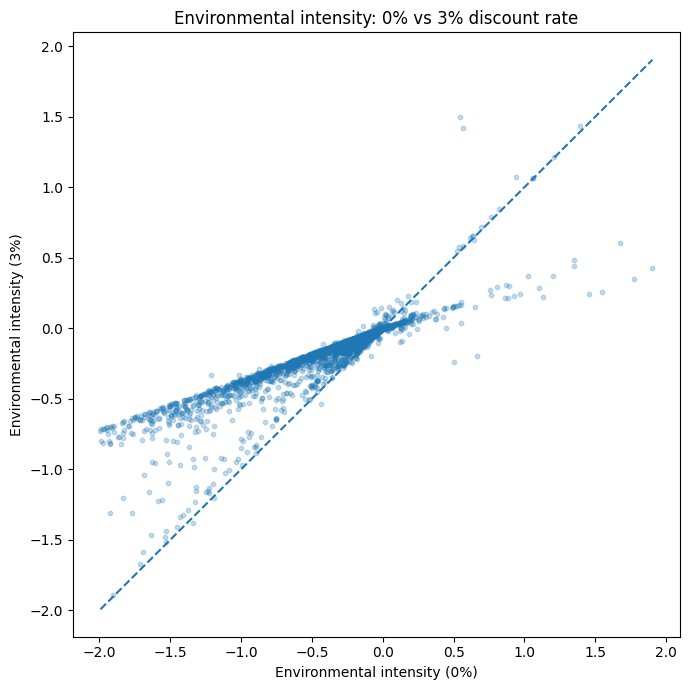

In [17]:
import matplotlib.pyplot as plt

# ============================================================
# 7. SENSITIVITY ANALYSIS: 0% vs 3%
# ============================================================

print("\n" + "=" * 70)
print("7. SENSITIVITY ANALYSIS: 0% VS 3%")
print("=" * 70)


def prepare_discount_sheet(data):

    temp = data.copy()

    temp = temp.drop(
        columns=["Environmental Intensity (Op Inc)"],
        errors="ignore"
    )

    temp.columns = [
        clean_column_name(col)
        for col in temp.columns
    ]

    string_cols = [
        "company_name",
        "country",
        "gics_sub_industry",
        "industry_exiobase"
    ]

    for col in string_cols:
        temp[col] = (
            temp[col]
            .astype("string")
            .str.strip()
        )

    # Create a stable within-group identifier for the rare cases where
    # the same company-year appears more than once. Sorting by % Imputed
    # preserves the natural pairing without requiring % Imputed itself
    # to be identical across discount-rate scenarios.
    pair_keys = [
        "year",
        "company_name",
        "gics_sub_industry",
        "industry_exiobase"
    ]

    temp = temp.sort_values(
        pair_keys + ["pct_imputed"],
        kind="stable"
    ).copy()

    temp["within_group_id"] = (
        temp.groupby(pair_keys, dropna=False)
        .cumcount()
    )

    return temp


discount_0 = prepare_discount_sheet(df_0_raw)
discount_3 = prepare_discount_sheet(df_3_raw)

pair_keys = [
    "year",
    "company_name",
    "gics_sub_industry",
    "industry_exiobase"
]

merge_keys = pair_keys + ["within_group_id"]

# Validate that the number of records within each pairing group is the same
# in both discount-rate sheets before merging.
group_counts_0 = discount_0.groupby(pair_keys, dropna=False).size()
group_counts_3 = discount_3.groupby(pair_keys, dropna=False).size()

group_count_check = (
    group_counts_0.to_frame("count_0pct")
    .join(group_counts_3.to_frame("count_3pct"), how="outer")
    .fillna(0)
)

group_count_mismatches = (
    group_count_check["count_0pct"]
    != group_count_check["count_3pct"]
).sum()

print("\nPairing groups with different record counts:", group_count_mismatches)

sensitivity = (
    discount_0[
        merge_keys
        + [
            "pct_imputed",
            "environmental_intensity_sales",
            "total_environmental_cost"
        ]
    ]
    .merge(
        discount_3[
            merge_keys
            + [
                "pct_imputed",
                "environmental_intensity_sales",
                "total_environmental_cost"
            ]
        ],
        on=merge_keys,
        how="inner",
        suffixes=("_0pct", "_3pct")
    )
)

matched_observations = len(sensitivity)
unmatched_0 = len(discount_0) - matched_observations
unmatched_3 = len(discount_3) - matched_observations
match_rate = matched_observations / max(len(discount_0), len(discount_3)) * 100

pct_imputed_changed = (
    sensitivity["pct_imputed_0pct"]
    .sub(sensitivity["pct_imputed_3pct"])
    .abs()
    .gt(1e-12)
    .sum()
)

print("\nTotal observations in 0% sheet:", len(discount_0))
print("Total observations in 3% sheet:", len(discount_3))
print("Matched observations:", matched_observations)
print("Unmatched observations in 0% sheet:", unmatched_0)
print("Unmatched observations in 3% sheet:", unmatched_3)
print(f"Match rate: {match_rate:.2f}%")
print("Matched pairs with different % Imputed:", pct_imputed_changed)


# ------------------------------------------------------------
# 7.1 Difference in intensity
# ------------------------------------------------------------

sensitivity["intensity_difference"] = (
    sensitivity[
        "environmental_intensity_sales_3pct"
    ]
    -
    sensitivity[
        "environmental_intensity_sales_0pct"
    ]
)

print("\nIntensity difference summary:")
print(
    sensitivity[
        "intensity_difference"
    ].describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
)


# ------------------------------------------------------------
# 7.2 Correlation between 0% and 3%
# ------------------------------------------------------------

discount_corr = (
    sensitivity[
        [
            "environmental_intensity_sales_0pct",
            "environmental_intensity_sales_3pct"
        ]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "\nCorrelation between 0% and 3% intensity:",
    discount_corr
)


# ------------------------------------------------------------
# 7.3 Scatterplot
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.scatter(
    sensitivity[
        "environmental_intensity_sales_0pct"
    ],
    sensitivity[
        "environmental_intensity_sales_3pct"
    ],
    alpha=0.25,
    s=10
)

min_value = min(
    sensitivity[
        "environmental_intensity_sales_0pct"
    ].min(),
    sensitivity[
        "environmental_intensity_sales_3pct"
    ].min()
)

max_value = max(
    sensitivity[
        "environmental_intensity_sales_0pct"
    ].max(),
    sensitivity[
        "environmental_intensity_sales_3pct"
    ].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(
    "Environmental intensity: 0% vs 3% discount rate"
)

plt.xlabel(
    "Environmental intensity (0%)"
)

plt.ylabel(
    "Environmental intensity (3%)"
)

plt.tight_layout()
plt.show()
